# 🏡 House Price Prediction Project

This project uses a simplified housing dataset to predict house prices using **Linear Regression**.

We'll walk through all steps including:
- Understanding the dataset
- Visualizing the data
- Preparing it for modeling
- Training and evaluating the model
- Plotting predictions

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/house_prices.csv')

# Preview the dataset
df.head()

,rooms,size,age,price
0,7,1640,13,292347.841482
1,4,2814,86,138201.609770
2,8,3032,35,301480.541060
3,5,4080,47,218169.717750
4,7,1687,86,212216.803456


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5130 entries, 0 to 5129
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   rooms   5130 non-null   int64  
 1   size    5130 non-null   int64  
 2   age     5130 non-null   int64  
 3   price   5130 non-null   float64
dtypes: float64(1), int64(3)
memory usage: 160.4 KB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
rooms,5130.0,4.993567,2.581591,1.000000,3.000000,5.000000,7.000000,9.000000
size,5130.0,2736.708967,1299.368171,501.000000,1595.250000,2749.000000,3863.750000,4998.000000
age,5130.0,49.728655,28.414894,1.000000,25.000000,50.000000,75.000000,99.000000
price,5130.0,204927.920738,89278.618544,-24616.914439,135308.539667,206198.097892,272998.079216,442658.278703


In [ ]:
df.isnull().sum()

,0
rooms,0
size,0
age,0
price,0


In [ ]:
df.duplicated().sum()

np.int64(0)

## 📊 Step 2: Explore and Visualize the Data

We visualize the relationships between features and the target (`price`) to get insights and detect any issues like skewness or outliers.

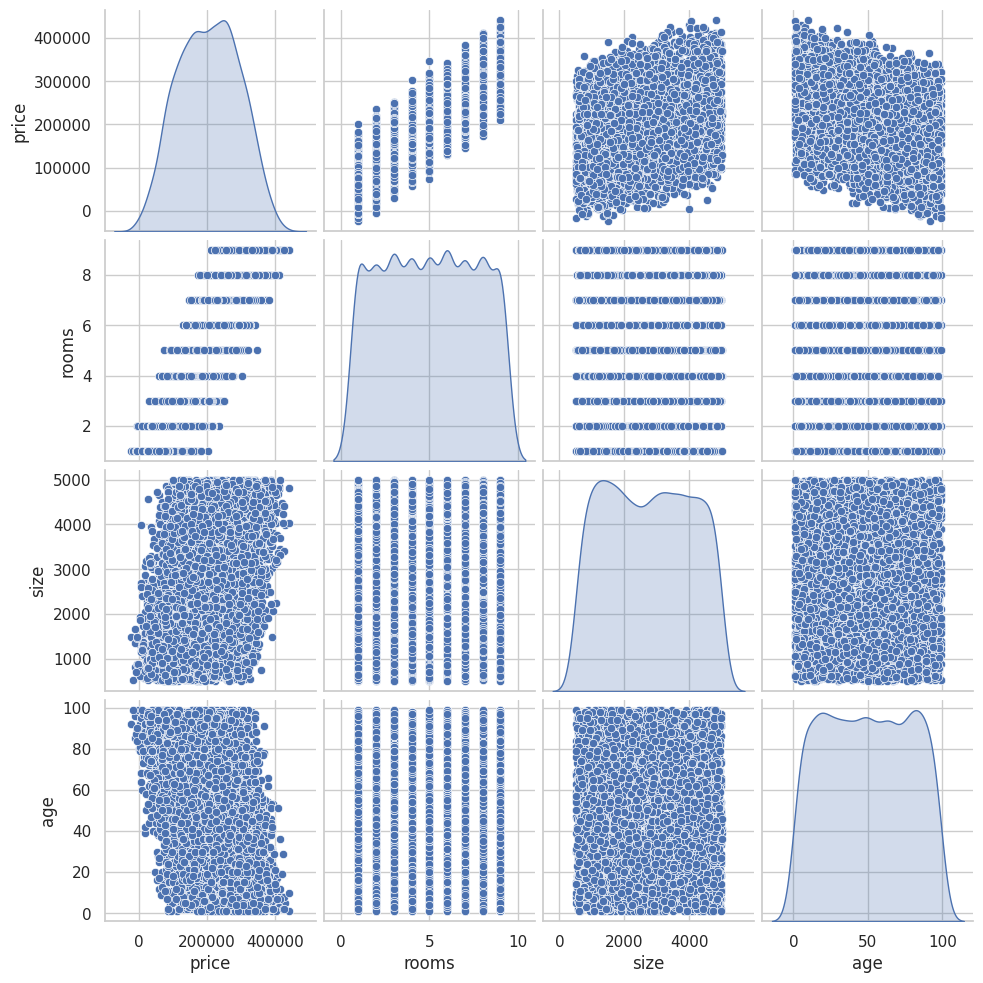

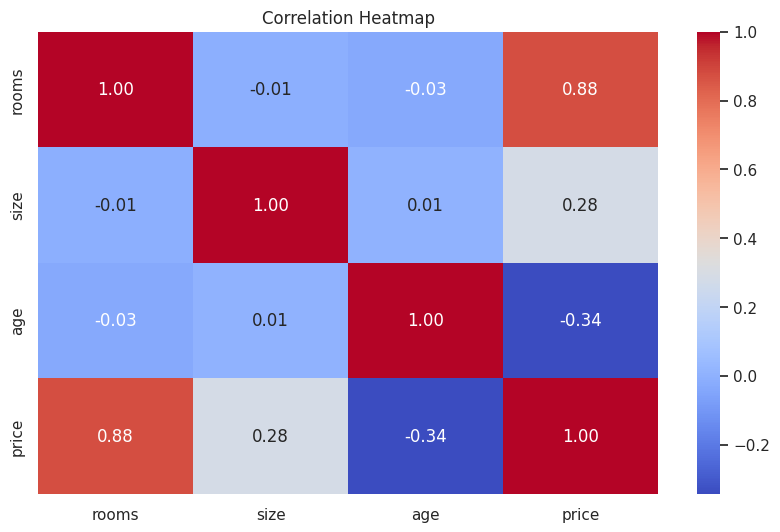

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn style
sns.set(style="whitegrid")

# Pairplot of selected numeric variables
sns.pairplot(df[['price', 'rooms', 'size', 'age']], diag_kind='kde')
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


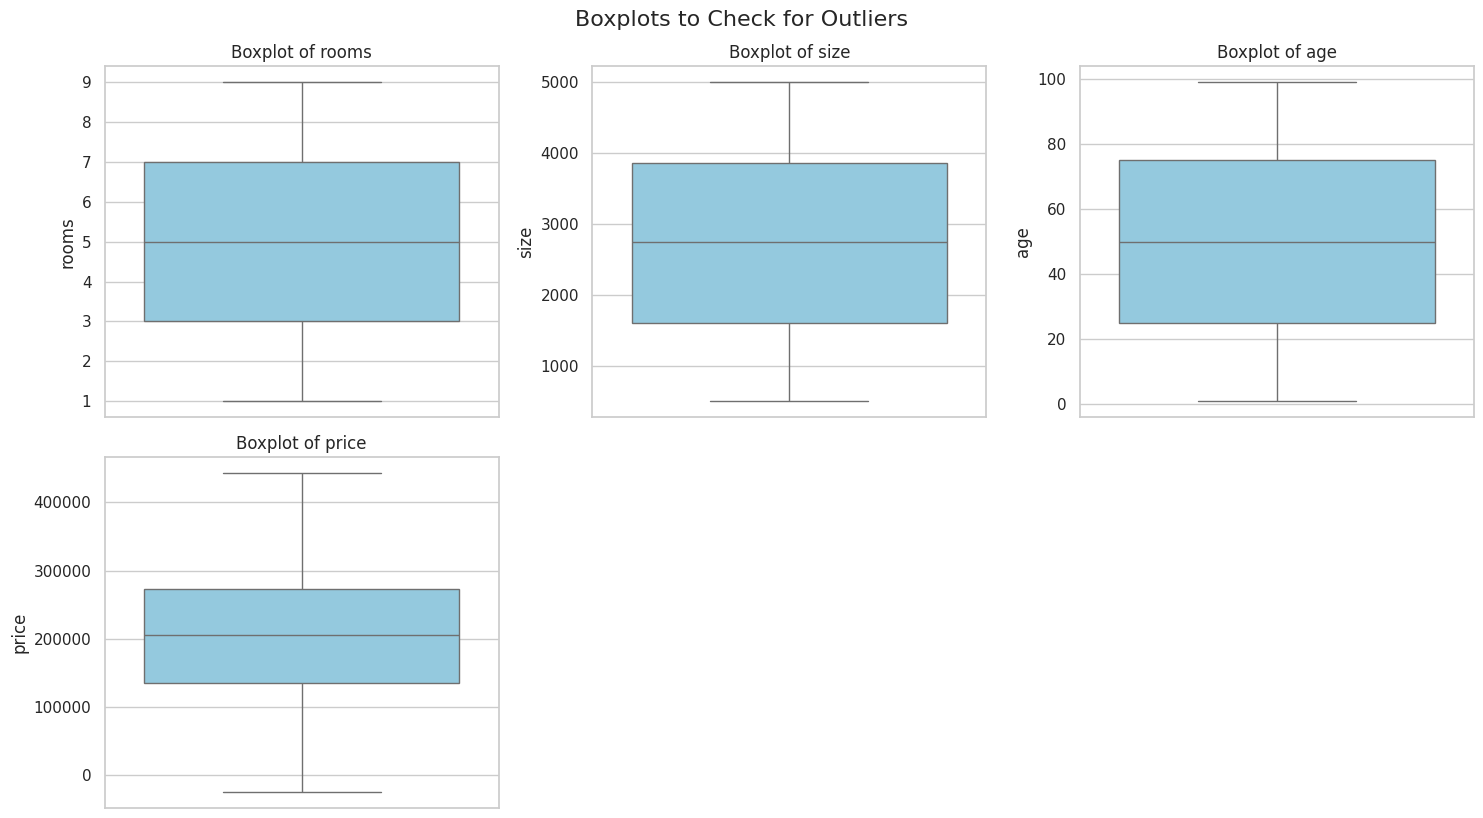

In [ ]:
# Select numerical features to check for outliers
features_to_check = ['rooms', 'size', 'age', 'price']

# Set up the matplotlib figure
plt.figure(figsize=(15, 8))

# Create boxplots for each feature
for i, feature in enumerate(features_to_check):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[feature], color='skyblue')
    plt.title(f'Boxplot of {feature}')
    plt.tight_layout()

plt.suptitle('Boxplots to Check for Outliers', fontsize=16, y=1.02)
plt.show()


## ✂️ Step 3: Prepare the Data for Modeling

We split the data into features (X) and target (y), and then into training and testing sets.

In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns='price')
y = df['price']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

Training set size: (4104, 3)
Test set size: (1026, 3)


## 🤖 Step 4: Train a Linear Regression Model

Now we train a linear regression model using the training data.

In [ ]:
from sklearn.linear_model import LinearRegression

# Initialize and fit the model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

## 📈 Step 5: Evaluate the Model

We evaluate model performance using common regression metrics on both training and test sets.


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Evaluation function
def evaluate(y_true, y_pred, dataset_name):
    print(f"\n{dataset_name} Set Evaluation:")
    print("MAE :", mean_absolute_error(y_true, y_pred))
    print("MSE :", mean_squared_error(y_true, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
    print("R²  :", r2_score(y_true, y_pred))

# Evaluate
evaluate(y_train, y_train_pred, "Training")
evaluate(y_test, y_test_pred, "Test")


Training Set Evaluation:
MAE : 15869.092097850591
MSE : 396605836.7983116
RMSE: 19914.965146801325
R²  : 0.9498075198187926

Test Set Evaluation:
MAE : 16641.527702740845
MSE : 433328716.31263494
RMSE: 20816.549097115854
R²  : 0.9473952882014464


## 🧾 Step 6: Plot Actual vs Predicted Prices

Finally, we visualize how well the model predicted house prices on the test set.


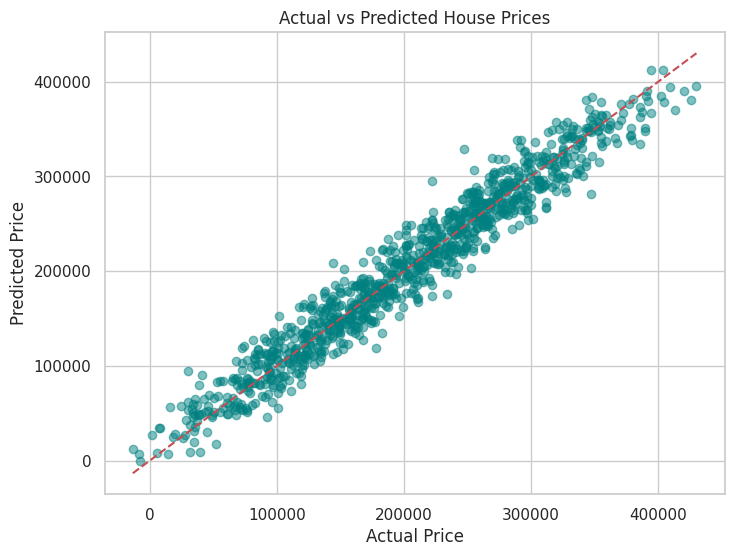

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.5, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.grid(True)
plt.show()